# 4. Học có giám sát – Phân loại Fake / True
Pipeline **TF-IDF → Multinomial Naive Bayes** và **TF-IDF → Passive-Aggressive Classifier (PA-I)** →
đánh giá trên tập test → kiểm tra bài gần trùng train/test → phân tích **từ khóa có trọng số cao nhất của mỗi lớp** → dự đoán bài mới.

In [1]:
import tempfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
LABELS = ["Fake", "True"]                                    # 0 = Fake, 1 = True
RESULTS_DIR, MODELS_DIR = Path("results/classification"), Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# keep_default_na=False: không để pandas biến các chuỗi như "null", "nan" thành giá trị thiếu
df = pd.read_csv("data/processed/news_clean.csv", keep_default_na=False)
print(f"{len(df):,} bài")

38,821 bài


### Chia train/test
Chia 80/20, giữ tỷ lệ nhãn. Tập test **chỉ dùng một lần** ở bước đánh giá cuối.

In [2]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)
print(f"Train: {len(X_train_text):,} bài | Test: {len(X_test_text):,} bài")

Train: 31,056 bài | Test: 7,765 bài


### Huấn luyện mô hình: Pipeline TF-IDF + classifier, chọn tham số bằng cross-validation
**Tránh rò rỉ giữa các fold.** TF-IDF (unigram + bigram, 50 000 đặc trưng) được đặt **trong cùng một `Pipeline`** với classifier và
`GridSearchCV` chạy trên **văn bản**. Ở mỗi fold, vocabulary, IDF và việc chọn `max_features` chỉ được tính trên phần train của fold đó;
fold validation hoàn toàn "chưa thấy" giống như dữ liệu mới. (Nếu fit TF-IDF trên toàn bộ train rồi mới đưa ma trận vào CV thì
IDF/vocabulary đã dùng cả fold validation → điểm CV lạc quan hơn thực tế.)
Để không phải fit lại TF-IDF cho từng giá trị tham số, Pipeline dùng `memory` (cache): mỗi fold chỉ fit TF-IDF **một lần**,
dùng chung cho mọi tham số và cả hai mô hình.

**Hai mô hình**
- **Naive Bayes**: `MultinomialNB`, tham số làm trơn `alpha`.
- **Passive-Aggressive (PA-I)**: từ scikit-learn 1.8, `PassiveAggressiveClassifier` bị deprecated và được thay bằng
  `SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1", eta0=C)` – **cùng một thuật toán**, `eta0` chính là `C`.
  Ở bản 1.9 lớp cũ còn có lỗi: `set_params(C=...)` bị bỏ qua nên `GridSearchCV` thực chất luôn dùng `C = 1`.

**Chọn tham số** bằng 5-fold CV (phân tầng, xáo trộn) trên tập train, lưới trải rộng nhiều bậc độ lớn.
Khi F1 gần như đi ngang (chênh lệch < 0.001 – nhỏ hơn dao động giữa các fold), ta chọn mô hình **điều chuẩn mạnh nhất**
trong vùng đó (NB: `alpha` lớn nhất, PA: `C` nhỏ nhất) – mô hình đơn giản hơn, ít bám vào từ hiếm, khái quát tốt hơn.

Naive Bayes       : chọn alpha = 0.001 | F1 CV = 0.9522 (tốt nhất trên lưới = 0.9529 tại alpha = 1e-05)


Passive-Aggressive: chọn C = 0.03 | F1 CV = 0.9899 (tốt nhất trên lưới = 0.9902 tại C = 0.3)


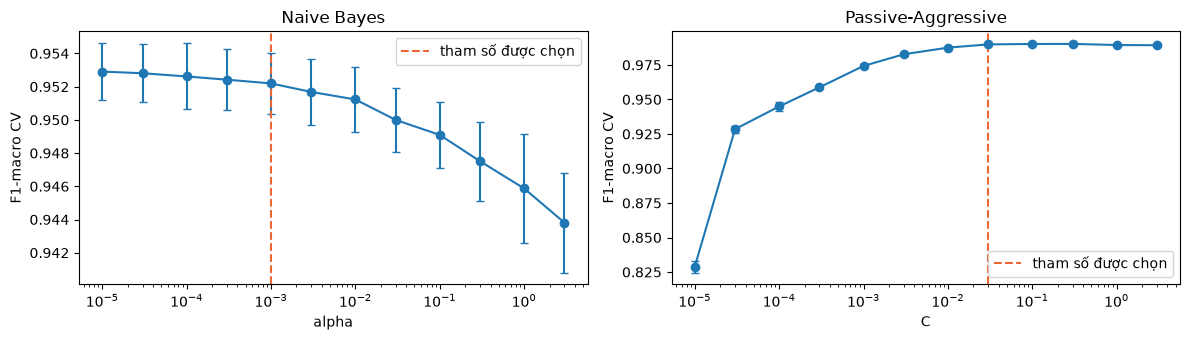

In [3]:
TFIDF_PARAMS = dict(ngram_range=(1, 2), max_features=50_000, min_df=3, max_df=0.9, sublinear_tf=True)
GRID = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
TOL = 0.001
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cache = Memory(tempfile.mkdtemp(prefix="tfidf_cache_"), verbose=0)


def build_pipeline(clf):
    return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_PARAMS)), ("clf", clf)], memory=cache)


def simplest_within_tol(param, larger_is_simpler):
    """refit cho GridSearchCV: chọn tham số điều chuẩn mạnh nhất có F1 CV >= F1 tốt nhất - TOL."""
    def pick(cv):
        scores, vals = cv["mean_test_score"], np.asarray(cv[f"param_{param}"], dtype=float)
        ok = np.flatnonzero(scores >= scores.max() - TOL)
        return int(ok[np.argmax(vals[ok])] if larger_is_simpler else ok[np.argmin(vals[ok])])
    return pick


SEARCH = {   # tên: (classifier, tham số cần dò, "giá trị lớn hơn = điều chuẩn mạnh hơn"?, nhãn hiển thị)
    "Naive Bayes": (MultinomialNB(), "clf__alpha", True, "alpha"),
    "Passive-Aggressive": (SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1",
                                         max_iter=1000, random_state=SEED), "clf__eta0", False, "C"),
}
models, cv_tables = {}, {}
for name, (clf, param, larger_is_simpler, label) in SEARCH.items():
    gs = GridSearchCV(build_pipeline(clf), {param: GRID}, cv=CV, scoring="f1_macro", n_jobs=1,
                      refit=simplest_within_tol(param, larger_is_simpler)).fit(X_train_text, y_train)
    models[name] = gs.best_estimator_.set_params(memory=None)     # bỏ cache trước khi lưu mô hình
    cv_tables[name] = pd.DataFrame({label: GRID, "F1 CV": gs.cv_results_["mean_test_score"],
                                    "std": gs.cv_results_["std_test_score"]})
    best_i = int(np.argmax(gs.cv_results_["mean_test_score"]))
    print(f"{name:<18}: chọn {label} = {GRID[gs.best_index_]:g} | F1 CV = {gs.cv_results_['mean_test_score'][gs.best_index_]:.4f} "
          f"(tốt nhất trên lưới = {gs.cv_results_['mean_test_score'][best_i]:.4f} tại {label} = {GRID[best_i]:g})")
cache.clear(warn=False)

pd.concat(cv_tables, names=["Mô hình"]).reset_index(level=0).to_csv(RESULTS_DIR / "cv_grid_search.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, t) in zip(axes, cv_tables.items()):
    label = SEARCH[name][3]
    ax.errorbar(t[label], t["F1 CV"], yerr=t["std"], marker="o", capsize=3)
    ax.axvline(models[name].get_params()[SEARCH[name][1]], color="#eb6834", ls="--", label="tham số được chọn")
    ax.set(xscale="log", title=name, xlabel=label, ylabel="F1-macro CV")
    ax.legend()
plt.tight_layout()
plt.show()

### Đánh giá trên tập test

===== Naive Bayes =====
              precision    recall  f1-score   support

        Fake     0.9444    0.9542    0.9493      3578
        True     0.9605    0.9520    0.9562      4187

    accuracy                         0.9530      7765
   macro avg     0.9524    0.9531    0.9527      7765
weighted avg     0.9531    0.9530    0.9530      7765



===== Passive-Aggressive =====
              precision    recall  f1-score   support

        Fake     0.9913    0.9866    0.9889      3578
        True     0.9886    0.9926    0.9906      4187

    accuracy                         0.9898      7765
   macro avg     0.9899    0.9896    0.9898      7765
weighted avg     0.9898    0.9898    0.9898      7765



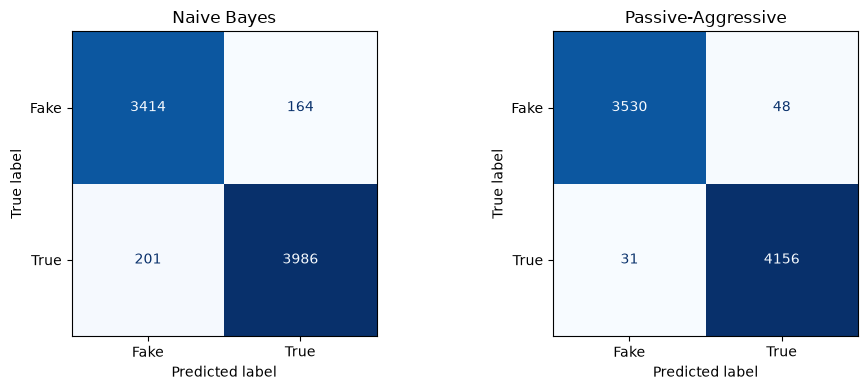

,Accuracy,F1-macro
Naive Bayes,0.9530,0.9527
Passive-Aggressive,0.9898,0.9898


In [4]:
results, test_pred = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = test_pred[name] = model.predict(X_test_text)
    results[name] = {"Accuracy": accuracy_score(y_test, pred), "F1-macro": f1_score(y_test, pred, average="macro")}
    print(f"===== {name} =====\n{classification_report(y_test, pred, target_names=LABELS, digits=4)}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=LABELS, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

metrics = pd.DataFrame(results).T.round(4)
metrics.to_csv(RESULTS_DIR / "test_metrics.csv")
metrics

### Kiểm tra bài gần trùng giữa test và train
Notebook 3 đã khử trùng **chính xác** theo thân bài. Ở đây kiểm tra thêm bài **gần trùng** (đăng lại có sửa vài câu):
với mỗi bài test, tính **cosine similarity lớn nhất** với các bài train trên vector TF-IDF (vectorizer fit trên train).
Nếu có nhiều bài test gần như sao chép một bài train thì accuracy test bị thổi phồng; ta so sánh accuracy trên toàn bộ test
và trên phần test **không** có bài gần trùng ở train.

Tương tự, gần như toàn bộ bài **chỉ có tiêu đề** (`title_only`) là tin Fake, nên cũng báo cáo accuracy khi bỏ các bài này.

In [5]:
tfidf = models["Naive Bayes"].named_steps["tfidf"]          # cả hai Pipeline fit TF-IDF giống hệt nhau trên train
X_tr, X_te = tfidf.transform(X_train_text), tfidf.transform(X_test_text)
max_sim = np.concatenate([(X_te[i:i + 250] @ X_tr.T).max(axis=1).toarray().ravel()
                          for i in range(0, X_te.shape[0], 250)])

near_dup = pd.DataFrame([{"Cosine ≥": t, "Số bài test": int((max_sim >= t).sum()),
                          "% test": round((max_sim >= t).mean() * 100, 2)} for t in [0.99, 0.95, 0.9, 0.8]])
display(near_dup)

THRESH = 0.8
keep = max_sim < THRESH
has_body = ~df.loc[X_test_text.index, "title_only"].astype(str).eq("True").to_numpy()
print(f"Tập test có {(~has_body).sum()} bài chỉ có tiêu đề:",
      y_test[~has_body].map(dict(enumerate(LABELS))).value_counts().to_dict())
acc = pd.DataFrame({name: {"Toàn bộ test": accuracy_score(y_test, p),
                           f"Bỏ bài có cosine ≥ {THRESH} với train": accuracy_score(y_test[keep], p[keep]),
                           "Bỏ bài chỉ có tiêu đề": accuracy_score(y_test[has_body], p[has_body])}
                    for name, p in test_pred.items()}).T.round(4)
near_dup.to_csv(RESULTS_DIR / "near_duplicates_test_train.csv", index=False)
acc.to_csv(RESULTS_DIR / "accuracy_without_near_duplicates.csv")
acc

,Cosine ≥,Số bài test,% test
0,0.99,7,0.09
1,0.95,26,0.33
2,0.90,59,0.76
3,0.80,125,1.61


Tập test có 113 bài chỉ có tiêu đề: {'Fake': 113}


,Toàn bộ test,Bỏ bài có cosine ≥ 0.8 với train,Bỏ bài chỉ có tiêu đề
Naive Bayes,0.9530,0.9526,0.9527
Passive-Aggressive,0.9898,0.9897,0.9897


### Từ khóa có trọng số cao nhất của mỗi lớp
- **Naive Bayes**: log-odds = log P(từ | True) − log P(từ | Fake).
- **Passive-Aggressive**: hệ số `coef_` của mô hình tuyến tính.

Ở cả hai, giá trị **dương → nghiêng về True**, **âm → nghiêng về Fake**.

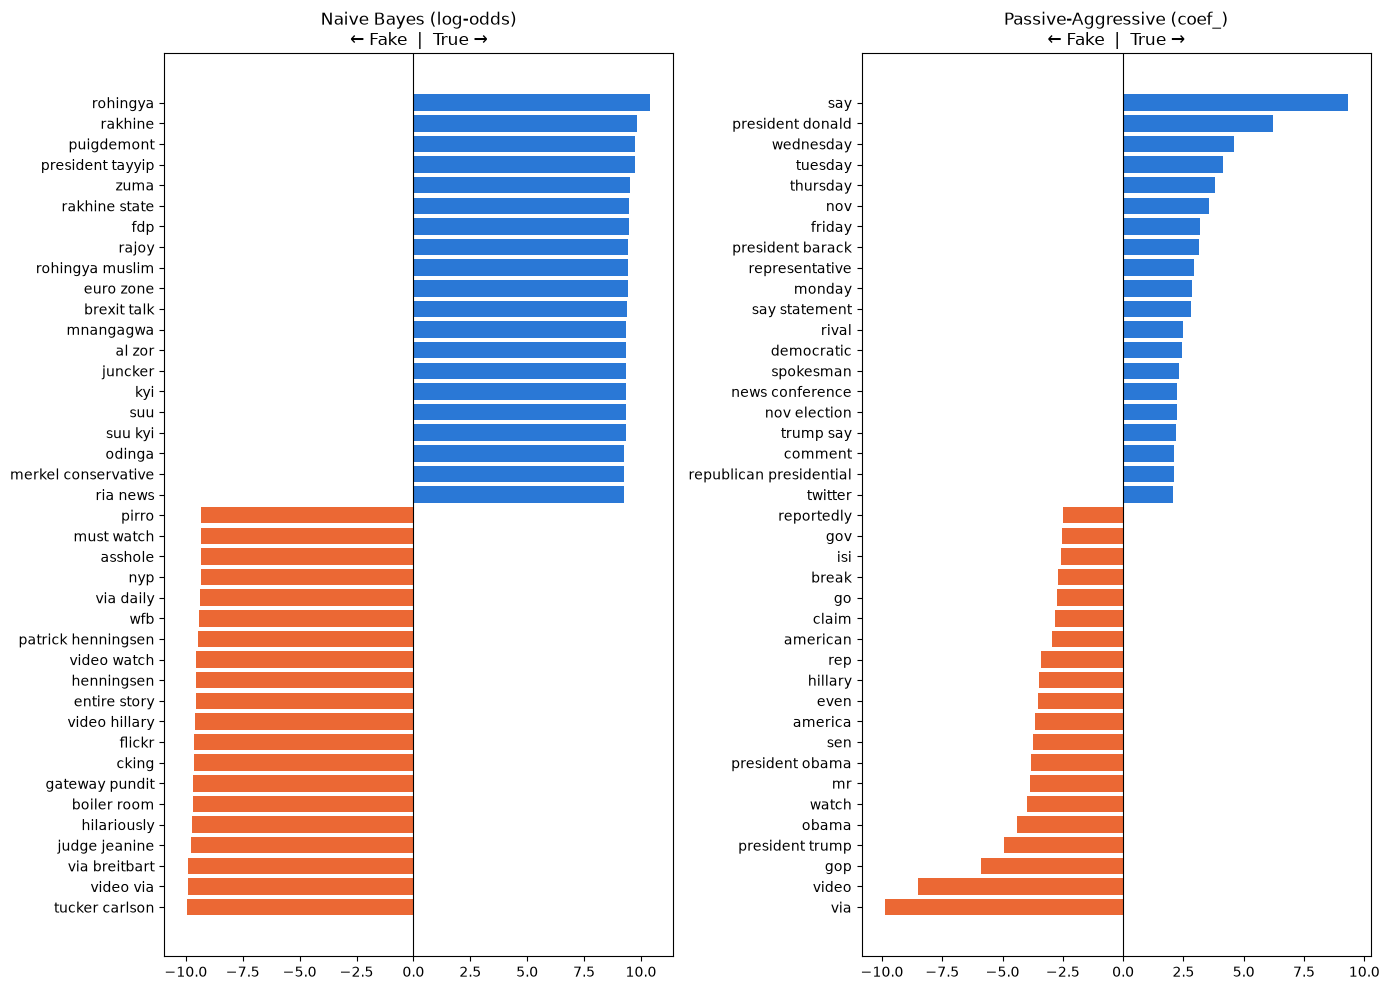

,Naive Bayes – Fake,Naive Bayes – True,Passive-Aggressive – Fake,Passive-Aggressive – True
0,tucker carlson,rohingya,via,say
1,video via,rakhine,video,president donald
2,via breitbart,puigdemont,gop,wednesday
3,judge jeanine,president tayyip,president trump,tuesday
4,hilariously,zuma,obama,thursday
5,boiler room,rakhine state,watch,nov
6,gateway pundit,fdp,mr,friday
7,cking,rajoy,president obama,president barack
8,flickr,rohingya muslim,sen,representative
9,video hillary,euro zone,america,monday


In [6]:
TOP = 20
terms = tfidf.get_feature_names_out()
nb, pa = models["Naive Bayes"].named_steps["clf"], models["Passive-Aggressive"].named_steps["clf"]
weights = {
    "Naive Bayes (log-odds)": pd.Series(nb.feature_log_prob_[1] - nb.feature_log_prob_[0], index=terms),
    "Passive-Aggressive (coef_)": pd.Series(pa.coef_[0], index=terms),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 10))
for ax, (name, w) in zip(axes, weights.items()):
    top = pd.concat([w.nsmallest(TOP), w.nlargest(TOP)]).sort_values()
    ax.barh(top.index, top.values, color=np.where(top > 0, "#2a78d6", "#eb6834"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{name}\n← Fake  |  True →")
plt.tight_layout()
plt.show()

top_keywords = pd.DataFrame({f"{name.split(' (')[0]} – {cls}": (w.nlargest(TOP) if cls == "True" else w.nsmallest(TOP)).index
                             for name, w in weights.items() for cls in LABELS})
top_keywords.to_csv(RESULTS_DIR / "top_keywords.csv", index=False)
top_keywords

### Từ khóa chung của cả hai mô hình
Từ nằm trong top 100 của **cả** NB và PA cho cùng một lớp – đây là những tín hiệu ổn định nhất, không phụ thuộc mô hình.

In [7]:
TOP_COMMON = 100
common = {cls: [t for t in pick(weights["Passive-Aggressive (coef_)"], TOP_COMMON).index
                if t in set(pick(weights["Naive Bayes (log-odds)"], TOP_COMMON).index)]
          for cls, pick in [("Fake", pd.Series.nsmallest), ("True", pd.Series.nlargest)]}
for cls, words in common.items():
    print(f"{cls} ({len(words)} từ): {', '.join(words[:30])}")

Fake (3 từ): wfb, nyp, entire story
True (0 từ): 


### Lưu mô hình và dự đoán bài mới
Mỗi mô hình được lưu dưới dạng **cả Pipeline** (TF-IDF + classifier) nên khi dùng lại không thể lỡ ghép nhầm vectorizer.
Bài mới đi qua **đúng hàm tiền xử lý đã dùng khi huấn luyện** – `preprocess_article` trong `text_preprocessing.py`.
Để kiểm chứng, lấy vài bài gốc của tập test (văn bản thô từ `data/raw`), tiền xử lý lại bằng hàm này và so với `clean_text` đã lưu ở notebook 3.

In [8]:
for name, model in models.items():
    joblib.dump(model, MODELS_DIR / f"{name.lower().replace('-', '_').replace(' ', '_')}.joblib")
print("Đã lưu:", sorted(p.name for p in MODELS_DIR.iterdir()))

Đã lưu: ['naive_bayes.joblib', 'passive_aggressive.joblib']


In [9]:
from text_preprocessing import preprocess_article


def predict_article(title, text, model_path=MODELS_DIR / "passive_aggressive.joblib"):
    """Dự đoán một bài báo thô (tiêu đề + thân bài) bằng mô hình đã lưu."""
    model = joblib.load(model_path)
    return LABELS[int(model.predict([preprocess_article(title, text)])[0])]


raw = pd.concat([pd.read_csv("data/raw/Fake.csv"), pd.read_csv("data/raw/True.csv")], ignore_index=True)
raw[["title", "text"]] = raw[["title", "text"]].fillna("")
demo = df.loc[X_test_text.index].groupby("label").sample(3, random_state=SEED)
rows = []
for _, r in demo.iterrows():
    art = raw.loc[r["raw_id"]]
    rows.append({"Tiêu đề": art["title"][:70], "Nhãn thật": LABELS[r["label"]],
                 "Dự đoán (PA)": predict_article(art["title"], art["text"]),
                 "Dự đoán (NB)": predict_article(art["title"], art["text"], MODELS_DIR / "naive_bayes.joblib"),
                 "Tiền xử lý khớp lúc huấn luyện": preprocess_article(art["title"], art["text"]) == r["clean_text"]})
pd.DataFrame(rows)

,Tiêu đề,Nhãn thật,Dự đoán (PA),Dự đoán (NB),Tiền xử lý khớp lúc huấn luyện
0,Democrats Go On The Attack Against Voter ID Laws,Fake,Fake,Fake,True
1,“Unvetted” Illegals Turn Germany Into A Third-...,Fake,Fake,Fake,True
2,Trump’s ICE Thugs Stop Ambulance Taking 10-Ye...,Fake,Fake,Fake,True
3,China summons British official over Hong Kong ...,True,True,True,True
4,Families chased from Libyan town in 2011 can g...,True,True,True,True
5,Turkish minister says will work to improve tie...,True,True,True,True


### Nhận xét

**1. Hiệu năng.** Passive-Aggressive đạt Accuracy / F1-macro ≈ **0.990** trên tập test, vượt Naive Bayes (≈ **0.953**).
- Điểm CV (không rò rỉ, TF-IDF fit lại trong từng fold) khớp với điểm test: PA 0.9899 so với 0.9898, NB 0.9522 so với 0.9527.
  Như vậy việc chọn tham số không bị lạc quan hóa, và tập test cho kết quả nhất quán với CV.
- Tham số được chọn (`alpha = 0.001`, `C = 0.03`) nằm giữa lưới. Đường cong CV gần như phẳng, nên kết quả không nhạy với tham số.
- NB giả định các từ độc lập và cho trọng số rất lớn những **từ hiếm** chỉ xuất hiện ở một lớp (top từ của NB toàn là tên riêng ít gặp).
  PA học trực tiếp ranh giới tuyến tính nên tận dụng được cả các **từ phổ biến** mang tín hiệu văn phong.

**2. Accuracy cao không đến từ bài trùng lặp.**
- Notebook 3 đã khử trùng chính xác theo thân bài (loại thêm các bài cùng thân bài nhưng khác tiêu đề).
- Chỉ **1.6 %** bài test có một bài train với cosine ≥ 0.8 (0.09 % có cosine ≥ 0.99). Bỏ các bài này đi, accuracy hầu như không đổi
  (PA 0.9898 → 0.9897, NB 0.9530 → 0.9526).
- Toàn bộ 113 bài test chỉ có tiêu đề đều là Fake. Bỏ chúng đi accuracy cũng gần như không đổi, nên các bài này không làm kết quả đẹp lên đáng kể.

**3. Từ khóa lớp True (tin thật – Reuters)**
- *PA*: `say`, `say statement`, `trump say`, `spokesman`, `news conference`, `comment`, các ngày trong tuần (`monday` … `friday`), `nov`.
  Đây là văn phong hãng tin: **trích dẫn nguồn** (*"..., X said on Tuesday"*), **mốc thời gian cụ thể** và
  chức danh đầy đủ (`president donald`, `president barack`, `representative`, `republican presidential`).
- *NB*: tên riêng thời sự quốc tế như `rohingya`, `rakhine`, `suu kyi`, `puigdemont`, `rajoy`, `zuma`, `mnangagwa`, `odinga`, `juncker`,
  `brexit talk`, `euro zone`. Nguyên nhân là cấu trúc dataset: chuyên mục `worldnews` **chỉ có ở lớp True** (xem EDA), nên mô hình học
  *"tin quốc tế ⇒ True"*. Đây là **thiên lệch chủ đề của dữ liệu**, không phải đặc điểm chung của tin thật.

**4. Từ khóa lớp Fake**
- *PA*: `video`, `watch`, `break` (*BREAKING*), `via`, `reportedly`, `claim`, `even`, `go`. Đây là kiểu **giật tít, kêu gọi xem video** và
  **dẫn lại nguồn khác** thay vì tự đưa tin. Ngoài ra còn cách gọi tắt `gop`, `sen`, `rep`, `gov`, `mr` (Reuters viết đầy đủ *Republican*, *Senator*),
  và việc nhắc nhiều `obama`, `hillary`, `isi(s)`, cho thấy nội dung công kích đảng phái.
- *NB*: các nguồn mà trang tin giả hay dẫn lại (`via breitbart`, `gateway pundit`, `wfb` = Washington Free Beacon, `nyp` = New York Post, `via daily`),
  người dẫn chương trình truyền hình (`tucker carlson`, `judge jeanine`, `pirro`), tác giả và chương trình của 21st Century Wire
  (`patrick henningsen`, `boiler room`), lời kêu gọi (`must watch`, `video watch`), và từ ngữ **cảm xúc, mỉa mai, thô tục**
  (`hilariously`, `asshole`, *f\*cking* → `cking`).
- Có 3 từ nằm trong top 100 lớp Fake của **cả hai** mô hình: `wfb`, `nyp`, `entire story` (*"read the entire story"*). Cả ba đều là thói quen
  **dẫn nguồn** của các trang tổng hợp tin.

**5. Mô hình thực sự học được gì, và giới hạn của kết quả.**
- Trước khi lọc ở notebook 3, top từ khóa gần như toàn là chú thích ảnh và câu chữ khuôn mẫu (`featured image`, `getty image`, `factbox`,
  `independently created` …). Sau khi lọc, độ chính xác chỉ giảm nhẹ và từ khóa còn lại phản ánh **văn phong** (trích dẫn, mốc thời gian
  so với giật tít, kêu gọi xem video) cùng **chủ đề** (tin quốc tế).
- Tuy vậy, mỗi lớp đến từ một nhóm nguồn cố định (True = Reuters, Fake = các trang bị PolitiFact/Wikipedia gắn cờ). Vì thế accuracy ≈ 99 %
  cho thấy mô hình phân biệt rất tốt *văn phong Reuters* với *văn phong các trang tin giả trong dataset này*. Nó **chưa chứng minh**
  mô hình nhận biết được tin đúng hay sai về nội dung.
- Hiệu năng trên nguồn tin khác (tin thật của báo khác, tin giả viết theo kiểu hãng tin) **chưa được kiểm chứng**.
  Hướng tiếp theo là đánh giá trên dữ liệu ngoài tập hiện tại, ví dụ LIAR, FakeNewsNet, hoặc tin thật từ báo khác Reuters.
